# What Drives Customer Satisfaction at Olist?
**SQL (SQLite) for data preparation · Python (pandas) for analysis**

Olist is a Brazilian e-commerce marketplace. This analysis uses ~100,000 real orders (2016–2018) across 9 related tables to answer one business question:

> **Which parts of the customer experience drive 1- and 2-star reviews, and where should operations focus first?**

**Workflow**
1. `src/build_database.py` loads the 9 CSVs into a SQLite database.
2. `sql/02_order_level_dataset.sql` joins 7 tables into one row per delivered, reviewed order.
3. `sql/03`–`06` aggregate by delivery timing, state, category and seller.
4. This notebook runs those queries and does the statistics and charts in pandas.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
from helpers import connect, run_sql_file, build_order_level, ols

IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)

# Chart style: one accent for "late", one for "on time", quiet axes
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

con = connect()

## 1. Data quality checks (SQL)
Checking the data before trusting it: table sizes, order statuses, duplicate reviews and missing values.

In [2]:
row_counts, statuses, multi_reviews, missing_delivery, missing_category = run_sql_file(con, "01_data_quality_checks.sql")
display(row_counts)
display(statuses)
print(f"Orders with 2+ reviews (kept latest only): {multi_reviews.iloc[0, 0]:,}")
print(f"Delivered orders with no delivery date (excluded): {missing_delivery.iloc[0, 0]:,}")
print(f"Products with no category (labeled 'unknown'): {missing_category.iloc[0, 0]:,}")

Orders with 2+ reviews (kept latest only): 547
Delivered orders with no delivery date (excluded): 8
Products with no category (labeled 'unknown'): 610


,table_name,row_count
0,orders,99441
1,order_items,112650
2,payments,103886
3,reviews,99224
4,customers,99441
5,sellers,3095
6,products,32951


,order_status,orders,pct_of_orders
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


## 2. Build the order-level dataset (SQL join of 7 tables)
`02_order_level_dataset.sql` collapses items, payments and reviews to one row per order *before* joining, so multi-item and split-payment orders don't inflate the totals. Only delivered orders with a delivery date and a review are kept.

In [3]:
build_order_level(con)
df = pd.read_sql("SELECT * FROM order_level", con, parse_dates=["purchase_date"])

assert df["order_id"].is_unique, "join created duplicate orders"
print(f"{len(df):,} orders | {df['customer_unique_id'].nunique():,} customers | "
      f"{df['seller_id'].nunique():,} sellers | {df['purchase_date'].min():%b %Y} to {df['purchase_date'].max():%b %Y}")
df.head()

95,824 orders | 92,747 customers | 2,954 sellers | Sep 2016 to Aug 2018


,order_id,customer_unique_id,customer_state,seller_id,seller_state,category,purchase_date,purchase_month,delivery_days,promised_days,days_vs_estimate,is_late,same_state,n_items,n_sellers,items_value,freight_value,freight_ratio,installments,main_payment_type,review_score,is_negative_review,left_comment
0,00010242fe8c5a6d1ba2dd792cb16214,871766c5855e863f6eccc05f988b23cb,RJ,48436dade18ac8b2bce089ec2a041202,SP,cool_stuff,2017-09-13,2017-09,7.61,15.63,-9.00,0,0,1,1,58.90,13.29,0.23,2.00,credit_card,5,0,1
1,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,SP,dd7ddc04e1b6c2c614352b383efe2d36,SP,pet_shop,2017-04-26,2017-04,16.22,18.55,-3.00,0,1,1,1,239.90,19.93,0.08,3.00,credit_card,4,0,0
2,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,MG,5b51032eddd242adc84c38acab88f23d,MG,furniture_decor,2018-01-14,2018-01,7.95,21.39,-14.00,0,1,1,1,199.00,17.87,0.09,5.00,credit_card,5,0,1
3,00024acbcdf0a6daa1e931b038114c75,af861d436cfc08b2c2ddefd0ba074622,SP,9d7a1d34a5052409006425275ba1c2b4,SP,perfumery,2018-08-08,2018-08,6.15,11.58,-6.00,0,1,1,1,12.99,12.79,0.98,2.00,credit_card,4,0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,64b576fb70d441e8f1b2d7d446e483c5,SP,df560393f3a51e74553ab94004ba5c87,PR,garden_tools,2017-02-04,2017-02,25.11,40.42,-16.00,0,0,1,1,199.90,18.14,0.09,3.00,credit_card,5,0,1


In [4]:
summary = pd.Series({
    "Average review (1-5)": df["review_score"].mean(),
    "% 5-star reviews": 100 * (df["review_score"] == 5).mean(),
    "% negative reviews (1-2 stars)": 100 * df["is_negative_review"].mean(),
    "% delivered after promised date": 100 * df["is_late"].mean(),
    "Median delivery time (days)": df["delivery_days"].median(),
    "Median promised time (days)": df["promised_days"].median(),
}).round(2)
summary.to_frame("value")

,value
Average review (1-5),4.16
% 5-star reviews,59.22
% negative reviews (1-2 stars),12.81
% delivered after promised date,6.66
Median delivery time (days),10.21
Median promised time (days),23.23


## 3. How much do late deliveries hurt reviews? (SQL aggregation)

In [5]:
buckets = run_sql_file(con, "03_late_delivery_impact.sql")[0]
buckets

,delivery_bucket,orders,pct_of_orders,avg_review,pct_negative_reviews,pct_five_star
0,1. 7+ days early,75744,79.00,4.31,9.00,63.40
1,2. 1-6 days early,12419,13.00,4.18,10.60,56.80
2,3. On the promised day,1280,1.30,4.03,12.40,50.60
3,4. 1-3 days late,1852,1.90,3.29,32.10,33.20
4,5. 4-7 days late,1748,1.80,2.10,67.70,14.10
5,6. 8+ days late,2781,2.90,1.70,79.30,7.00


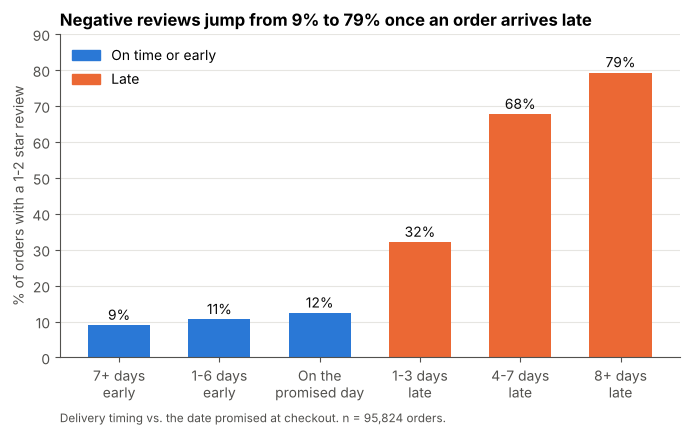

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
labels = buckets["delivery_bucket"].str.slice(3).str.replace(" days ", " days\n", regex=False).str.replace("the promised", "the\npromised", regex=False)
colors = [ORANGE if "late" in b else BLUE for b in buckets["delivery_bucket"]]
bars = ax.bar(labels, buckets["pct_negative_reviews"], color=colors, width=0.62)
for bar, value in zip(bars, buckets["pct_negative_reviews"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1.5, f"{value:.0f}%",
            ha="center", color=INK, fontsize=10)
ax.set_ylabel("% of orders with a 1-2 star review")
ax.set_ylim(0, 90)
ax.grid(axis="x", visible=False)
ax.set_title("Negative reviews jump from 9% to 79% once an order arrives late")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="On time or early"), Patch(color=ORANGE, label="Late")],
          frameon=False, loc="upper left")
ax.text(0, -0.2, f"Delivery timing vs. the date promised at checkout. n = {buckets['orders'].sum():,} orders.",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
fig.savefig(IMAGES / "01_late_delivery_reviews.png")
plt.show()

In [7]:
late = df[df["is_late"] == 1]
on_time = df[df["is_late"] == 0]
late_neg, on_time_neg = late["is_negative_review"].mean(), on_time["is_negative_review"].mean()
chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(df["is_late"], df["is_negative_review"]))

print(f"Late orders:    {len(late):>6,} ({len(late) / len(df):.1%}) | negative review rate {late_neg:.1%}")
print(f"On-time orders: {len(on_time):>6,} ({len(on_time) / len(df):.1%}) | negative review rate {on_time_neg:.1%}")
print(f"Late orders are {late_neg / on_time_neg:.1f}x as likely to get a 1-2 star review (chi-square p = {p:.1e})")

# Share of ALL negative reviews that come from the 6.7% of orders that were late
share = late["is_negative_review"].sum() / df["is_negative_review"].sum()
print(f"Late orders are {len(late) / len(df):.1%} of orders but {share:.1%} of all negative reviews")

Late orders:     6,381 (6.7%) | negative review rate 62.4%
On-time orders: 89,443 (93.3%) | negative review rate 9.3%
Late orders are 6.7x as likely to get a 1-2 star review (chi-square p = 0.0e+00)
Late orders are 6.7% of orders but 32.5% of all negative reviews


## 4. What else drives the review score? (multiple regression in pandas/numpy)
Late delivery could be standing in for other problems (expensive orders, high shipping costs, multi-seller orders). A regression holds those constant. Robust (HC1) standard errors are used because review scores have unequal variance.

In [8]:
model_df = pd.DataFrame({
    "review_score":       df["review_score"],
    "is_late":            df["is_late"],
    "days_late":          df["days_vs_estimate"].clip(lower=0),          # 0 if on time
    "delivery_days":      df["delivery_days"],
    "multi_seller_order": (df["n_sellers"] > 1).astype(int),
    "n_items":            df["n_items"],
    "freight_ratio":      df["freight_ratio"].clip(upper=1),              # cap extreme outliers
    "log_order_value":    np.log(df["items_value"]),
    "installments":       df["installments"],
    "same_state_seller":  df["same_state"],
}).dropna()

predictors = model_df.columns.drop("review_score")
coefs, r2, n = ols(model_df["review_score"], model_df[predictors])
print(f"n = {n:,}   R-squared = {r2:.3f}")
coefs.round(4)

n = 95,823   R-squared = 0.197


,coef,std_err,t,p_value,ci_low,ci_high
intercept,4.86,0.04,128.98,0.00,4.79,4.94
is_late,-1.57,0.03,-51.60,0.00,-1.63,-1.51
days_late,0.01,0.00,5.48,0.00,0.01,0.02
delivery_days,-0.03,0.00,-36.57,0.00,-0.03,-0.03
multi_seller_order,-1.16,0.05,-23.61,0.00,-1.26,-1.07
n_items,-0.25,0.01,-21.76,0.00,-0.27,-0.23
freight_ratio,0.01,0.03,0.26,0.80,-0.05,0.06
log_order_value,0.01,0.01,1.74,0.08,-0.00,0.03
installments,-0.00,0.00,-2.92,0.00,-0.01,-0.00
same_state_seller,-0.07,0.01,-7.22,0.00,-0.09,-0.05


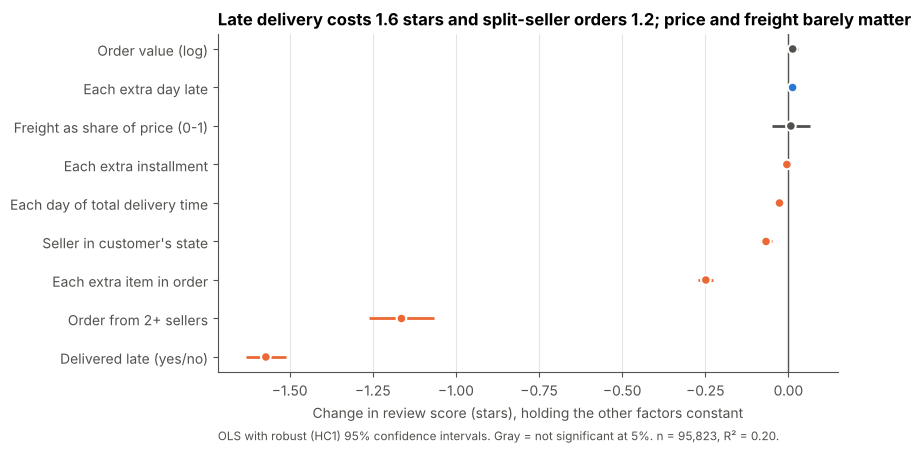

In [9]:
plot = coefs.drop("intercept").sort_values("coef")
names = {
    "is_late": "Delivered late (yes/no)", "days_late": "Each extra day late",
    "delivery_days": "Each day of total delivery time", "multi_seller_order": "Order from 2+ sellers",
    "n_items": "Each extra item in order", "freight_ratio": "Freight as share of price (0-1)",
    "log_order_value": "Order value (log)", "installments": "Each extra installment",
    "same_state_seller": "Seller in customer's state",
}
fig, ax = plt.subplots(figsize=(8, 4.4))
y = np.arange(len(plot))
point_colors = [ORANGE if c < 0 and pv < 0.05 else (BLUE if pv < 0.05 else MUTED)
                for c, pv in zip(plot["coef"], plot["p_value"])]
ax.hlines(y, plot["ci_low"], plot["ci_high"], color=point_colors, linewidth=2)
ax.scatter(plot["coef"], y, color=point_colors, s=48, zorder=3, edgecolor="white", linewidth=1.5)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, [names[i] for i in plot.index])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Change in review score (stars), holding the other factors constant")
ax.set_title("Late delivery costs 1.6 stars and split-seller orders 1.2; price and freight barely matter")
ax.text(0, -0.2, f"OLS with robust (HC1) 95% confidence intervals. Gray = not significant at 5%. n = {n:,}, R² = {r2:.2f}.",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
fig.savefig(IMAGES / "02_regression_drivers.png")
plt.show()

### 4b. Why do orders from 2+ sellers score so badly?
Only 1.3% of orders are split across sellers, but the regression says they cost over a full star, and they are rarely flagged as late. A hypothesis: each seller ships separately, so customers review before every package arrives. The review comments (Portuguese) can test that.

In [10]:
multi = df["n_sellers"] > 1
print(f"Split-seller orders: {multi.sum():,} ({multi.mean():.1%}) | negative review rate "
      f"{df.loc[multi, 'is_negative_review'].mean():.1%} vs {df.loc[~multi, 'is_negative_review'].mean():.1%} | "
      f"late rate {df.loc[multi, 'is_late'].mean():.1%} vs {df.loc[~multi, 'is_late'].mean():.1%}")

comment_query = (
    "SELECT o.n_sellers, LOWER(r.review_comment_message) AS msg "
    "FROM order_level AS o JOIN reviews AS r USING (order_id) "
    "WHERE o.is_negative_review = 1 AND r.review_comment_message IS NOT NULL"
)
comments = pd.read_sql(comment_query, con)

# Portuguese phrases for "missing", "only received one", "didn't receive", "incomplete"
missing_items = (r"(?:faltou|falta|faltando|apenas um|só um|so um|somente um|não recebi|nao recebi|"
                 r"recebi apenas|recebi só|recebi so|um dos|incompleto|metade)")
comments["mentions_missing_items"] = comments["msg"].str.contains(missing_items)
(comments.assign(order_type=np.where(comments["n_sellers"] > 1, "2+ sellers", "1 seller"))
         .groupby("order_type")
         .agg(negative_comments=("msg", "size"), pct_mentioning_missing_items=("mentions_missing_items", "mean"))
         .assign(pct_mentioning_missing_items=lambda t: 100 * t["pct_mentioning_missing_items"]))

Split-seller orders: 1,261 (1.3%) | negative review rate 47.2% vs 12.3% | late rate 1.0% vs 6.7%


,negative_comments,pct_mentioning_missing_items
order_type,,
1 seller,8764,23.77
2+ sellers,508,56.89


## 5. Where are deliveries late? (state-level SQL with window ranking)

In [11]:
states = run_sql_file(con, "04_state_performance.sql")[0]
states

,customer_state,orders,avg_delivery_days,pct_late,avg_review,pct_negative_reviews,pct_same_state_seller,late_rank
0,MA,712,21.40,17.10,3.83,19.90,2.00,1
1,CE,1273,21.20,13.70,3.94,17.10,0.70,2
2,BA,3229,19.20,11.90,3.93,17.00,2.00,3
3,RJ,12211,15.20,11.90,3.97,18.30,7.70,3
4,PA,933,23.60,10.70,3.91,17.90,0.00,5
5,ES,1969,15.60,10.40,4.08,13.80,0.30,6
6,PB,512,20.20,10.20,4.08,14.80,0.20,7
7,MS,699,15.60,9.70,4.16,13.30,0.00,8
8,PE,1579,18.40,9.40,4.08,14.80,1.50,9
9,SC,3519,14.90,8.10,4.13,13.00,7.20,10


Correlation between state late rate and average review: r = -0.91, p = 2.9e-07


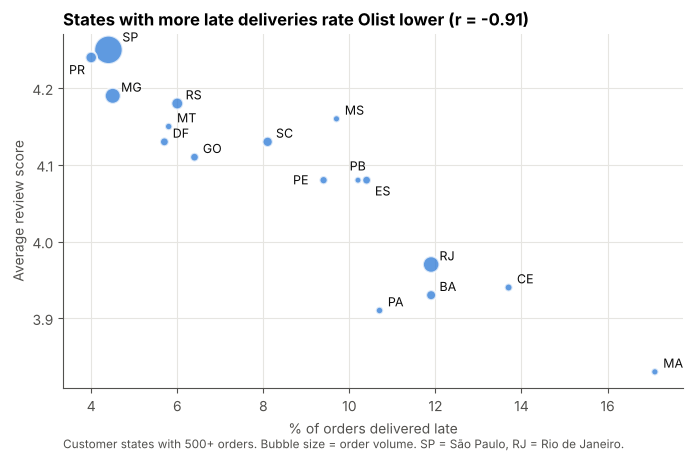

In [12]:
r, p_state = stats.pearsonr(states["pct_late"], states["avg_review"])
fig, ax = plt.subplots(figsize=(8, 4.6))
sizes = 20 + states["orders"] / states["orders"].max() * 400
ax.scatter(states["pct_late"], states["avg_review"], s=sizes, color=BLUE, alpha=0.75, edgecolor="white", linewidth=1.5)
offsets = {"SP": (10, 6), "PR": (-16, -12), "PE": (-22, -3), "PB": (-6, 7), "ES": (6, -11)}  # avoid overlapping labels
for _, row in states.iterrows():
    ax.annotate(row["customer_state"], (row["pct_late"], row["avg_review"]),
                xytext=offsets.get(row["customer_state"], (6, 3)),
                textcoords="offset points", fontsize=9, color=INK)
ax.set_xlabel("% of orders delivered late")
ax.set_ylabel("Average review score")
ax.set_title(f"States with more late deliveries rate Olist lower (r = {r:.2f})")
ax.text(0, -0.17, "Customer states with 500+ orders. Bubble size = order volume. SP = São Paulo, RJ = Rio de Janeiro.",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
fig.savefig(IMAGES / "03_state_late_vs_review.png")
plt.show()
print(f"Correlation between state late rate and average review: r = {r:.2f}, p = {p_state:.1e}")

## 6. Is lateness getting better or worse over time?

Month-level correlation (late rate vs avg review): r = -0.92


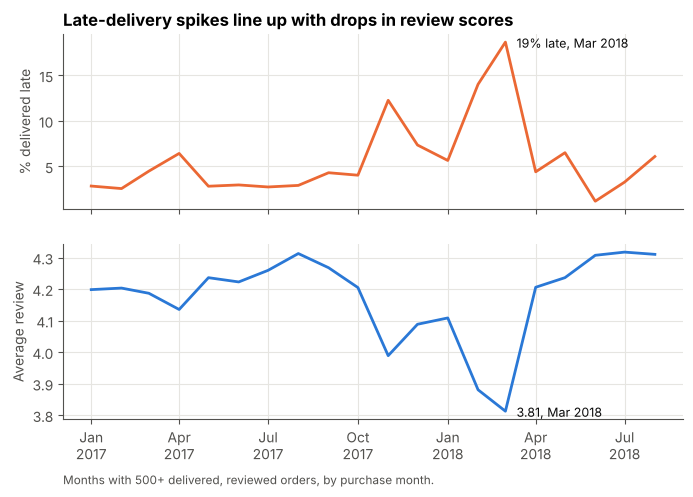

In [13]:
monthly = (df.groupby("purchase_month")
             .agg(orders=("order_id", "count"), pct_late=("is_late", "mean"), avg_review=("review_score", "mean"))
             .query("orders >= 500"))
monthly["pct_late"] *= 100
monthly.index = pd.to_datetime(monthly.index)

# Two measures on different scales -> two stacked panels, never a dual axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax1.plot(monthly.index, monthly["pct_late"], color=ORANGE, linewidth=2)
ax1.set_ylabel("% delivered late")
ax1.set_title("Late-delivery spikes line up with drops in review scores")
ax2.plot(monthly.index, monthly["avg_review"], color=BLUE, linewidth=2)
ax2.set_ylabel("Average review")
peak = monthly["pct_late"].idxmax()
ax1.annotate(f"{monthly.loc[peak, 'pct_late']:.0f}% late, {peak:%b %Y}", (peak, monthly.loc[peak, "pct_late"]),
             xytext=(8, -4), textcoords="offset points", fontsize=9, color=INK)
low = monthly["avg_review"].idxmin()
ax2.annotate(f"{monthly.loc[low, 'avg_review']:.2f}, {low:%b %Y}", (low, monthly.loc[low, "avg_review"]),
             xytext=(8, -4), textcoords="offset points", fontsize=9, color=INK)
import matplotlib.dates as mdates
ax2.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.text(0.125, -0.02, "Months with 500+ delivered, reviewed orders, by purchase month.", color=MUTED, fontsize=8.5)
fig.savefig(IMAGES / "04_monthly_trend.png")
plt.show()
print(f"Month-level correlation (late rate vs avg review): r = {monthly['pct_late'].corr(monthly['avg_review']):.2f}")

## 7. Category performance (SQL)

In [14]:
categories = run_sql_file(con, "05_category_performance.sql")[0]
categories

,category,orders,revenue_brl,avg_order_value_brl,avg_freight_pct_of_price,pct_late,avg_review
0,health_beauty,8567,"1,225,360.00",143.03,27.90,7.40,4.23
1,watches_gifts,5436,"1,159,947.00",213.38,16.50,7.30,4.12
2,bed_bath_table,9090,"1,014,374.00",111.59,27.20,7.30,4.01
3,sports_leisure,7448,"948,455.00",127.34,28.20,6.50,4.23
4,computers_accessories,6480,"884,519.00",136.50,29.80,6.30,4.08
5,furniture_decor,6142,"703,674.00",114.57,32.40,7.10,4.08
6,housewares,5646,"611,275.00",108.27,37.50,5.30,4.20
7,cool_stuff,3502,"603,390.00",172.30,20.80,5.80,4.23
8,auto,3774,"571,734.00",151.49,32.20,7.20,4.15
9,toys,3757,"467,208.00",124.36,26.10,6.20,4.24


## 8. Seller scorecard (SQL with CTEs, CROSS JOIN benchmark and RANK)
Sellers with 100+ orders are flagged when both their late rate and negative-review rate are at least 1.5x the marketplace average.

In [15]:
sellers = run_sql_file(con, "06_seller_scorecard.sql")[0]
flagged = sellers[sellers["flag"] == "Review operations"]
print(f"{len(sellers)} sellers have 100+ orders; {len(flagged)} are flagged for an operations review.")
print(f"Flagged sellers: {flagged['orders'].sum():,} orders, "
      f"avg review {np.average(flagged['avg_review'], weights=flagged['orders']):.2f} "
      f"vs {np.average(sellers['avg_review'], weights=sellers['orders']):.2f} for all 100+ order sellers")
flagged.assign(seller_id=flagged["seller_id"].str.slice(0, 8) + "…")

204 sellers have 100+ orders; 8 are flagged for an operations review.
Flagged sellers: 1,551 orders, avg review 3.54 vs 4.13 for all 100+ order sellers


,seller_id,seller_state,orders,revenue_brl,pct_late,pct_negative_reviews,avg_review,flag,revenue_rank
0,2eb70248…,SP,183,"37,584.00",10.90,47.50,2.78,Review operations,50
1,1835b56c…,SP,397,"33,740.00",10.80,22.70,3.70,Review operations,58
2,88460e8e…,PR,231,"30,694.00",17.70,29.00,3.48,Review operations,67
3,855668e0…,SP,293,"30,167.00",12.30,20.10,3.87,Review operations,68
4,59b22a78…,MG,122,"26,919.00",11.50,19.70,4.00,Review operations,74
5,431af27f…,SP,114,"12,705.00",14.00,22.80,3.82,Review operations,133
6,1ca7077d…,SP,107,"12,394.00",16.80,59.80,2.39,Review operations,136
7,b1fc4f64…,RJ,104,"8,114.00",12.50,21.20,3.85,Review operations,173


## 9. Business impact: what is fixing late delivery worth?
If late orders received negative reviews at the same rate as on-time orders, how many negative reviews disappear?

In [16]:
current_negative = df["is_negative_review"].sum()
avoidable = len(late) * (late_neg - on_time_neg)
print(f"Current negative reviews:                     {current_negative:,.0f} ({current_negative / len(df):.1%} of orders)")
print(f"Avoidable if late orders matched on-time:     {avoidable:,.0f}")
print(f"Negative-review rate after the fix:           {(current_negative - avoidable) / len(df):.1%}")
print(f"Reduction in negative reviews:                {avoidable / current_negative:.0%}")

# Olist's promised dates are padded: most orders arrive far earlier than promised
early_days = -df.loc[df["is_late"] == 0, "days_vs_estimate"]
print(f"\nOn-time orders arrive a median of {early_days.median():.0f} days before the promised date.")

Current negative reviews:                     12,272 (12.8% of orders)
Avoidable if late orders matched on-time:     3,392
Negative-review rate after the fix:           9.3%
Reduction in negative reviews:                28%

On-time orders arrive a median of 13 days before the promised date.


## 10. Findings and recommendations

1. **Late delivery is the #1 driver of bad reviews.** Only 6.7% of orders arrive late, but they produce 32.5% of all 1–2 star reviews. Late orders are 6.7x as likely to get a negative review (62% vs 9%), and the regression shows being late costs about 1.6 stars after controlling for delivery time, basket size, price, freight and seller location.
2. **Missing the promise matters more than speed.** On-time orders arrive a median of 13 days *early*; the score drops sharply only once the promised date passes (32% negative at 1–3 days late, 79% at 8+ days late).
3. **Split-seller orders are a hidden problem.** Orders from 2+ sellers are just 1.3% of volume but get 47% negative reviews (−1.2 stars in the regression), and 57% of their negative comments mention missing or partial items vs 24% for single-seller orders. Customers appear to review before every package arrives.
4. **Lateness is concentrated in the Northeast and Rio de Janeiro.** MA, CE, BA and RJ have the highest late rates (12–17%) and lowest scores; across states, late rate and average review correlate at r = −0.91. These states also have long delivery times and almost no in-state sellers.
5. **A short list of sellers needs attention.** 8 of the 204 sellers with 100+ orders have late and negative-review rates both 1.5x the marketplace average (average review 3.54 vs 4.13).

**Business impact:** if late orders received negative reviews at the on-time rate, negative reviews would fall by about 3,400 (28%), from 12.8% to 9.3% of orders.

**Recommendations**
- **Protect the promised date in high-risk states.** Add buffer to estimates and prioritize carriers for MA, CE, BA, PA and RJ, where late rates are 2–4x São Paulo's.
- **Fix the split-order experience.** Tell customers up front that items ship separately, send the review request only after the *last* package arrives, and show per-package tracking.
- **Proactive delay alerts.** Notify customers before a promised date is missed; the drop in score happens at the promise, so expectation management is the lever.
- **Seller operations reviews.** Start with the 8 flagged sellers and tie search ranking to on-time performance.

**Limitations:** observational data, so effects are associations, not proven causes. Reviews are self-selected, the keyword check on comments is approximate, and the data ends in 2018.